In [1]:
#general operations
import pandas as pd
import numpy as np
import pyomo.environ as pyo
import logging
from pyomo.environ import *
from pyomo.util.infeasible import log_infeasible_constraints
# 1. Configure the logger to display INFO level messages
logging.basicConfig(level=logging.INFO)
from pyomo.util.infeasible import find_infeasible_constraints
from pyomo.opt import SolverFactory, SolverStatus, TerminationCondition

import seaborn as sns
import matplotlib.pyplot as plt
import matplotlib
import matplotlib.colors as mcolors

# Building a Material flow analysis (MFA) of plastic from the Canadian Supply-use tables (SUTs)

## Import data and create base tables
Parameters: Importing and cleaning of primary Supply-use table data

In [2]:
#load Use table of the corresponding year
year = 2019 #2014, 2015, 2016, 2017, 2018, 2019, 2020, 2021, 2022
#Use table
file_path = f'Raw data/CA_SUT_C{year}_D.xlsx'
U_table = pd.read_excel(file_path, sheet_name='Use_Basic',index_col=0)

#clean imported Use table df for year=[2018,2019,2020,2021,2022]
U_table = U_table.reset_index(drop=True) #drop first column
U_table = U_table.drop(index=[0,1,2]) #drop all empty rows at the top
#rename row with NAICS codes accordingly
U_table.iloc[1,0] = 'Industry Code (NAICS)'


#rename duplicate industries, i.e. 'Educational services', 'Social assistance', and 'Nursing and residential care facilities' to differentiate private, non-profit, and government services and have unique industry (column) labels
#Educational services (BS610000)
mask = U_table.eq('BS610000')
row_idx, col_idx = mask.stack().idxmax()
U_table.loc[row_idx - 1, col_idx] = 'Educational services, private'
#and (NP610000)
mask = U_table.eq('NP610000')
row_idx, col_idx = mask.stack().idxmax()
U_table.loc[row_idx - 1, col_idx] = 'Educational services, non-profit'

#Social assistance (NP624000) 
mask = U_table.eq('NP624000')
row_idx, col_idx = mask.stack().idxmax()
U_table.loc[row_idx - 1, col_idx] = 'Social assistance, non-profit'
# and (BS624000)
mask = U_table.eq('BS624000')
row_idx, col_idx = mask.stack().idxmax()
U_table.loc[row_idx - 1, col_idx] = 'Social assistance, private'

#Nursing and residential care facilities (BS623000)
mask = U_table.eq('BS623000')
row_idx, col_idx = mask.stack().idxmax()
U_table.loc[row_idx - 1, col_idx] = 'Nursing and residential care facilities, private'
# and (GS623000)
mask = U_table.eq('GS623000')
row_idx, col_idx = mask.stack().idxmax()
U_table.loc[row_idx - 1, col_idx] = 'Nursing and residential care facilities, government'


#use first row as column labels
U_table.columns = U_table.iloc[0]   # use first row for column names
U_table = U_table[2:]               # remove the first two rows from the data
U_table = U_table.reset_index(drop=True)  # reset row indices

#rename fist column label 'Products' and set as index
U_table.columns.values[0] = 'Products'
U_table.index.name = None       #remove name of indices
U_table.columns.name = None     #remove name of columns
U_table.set_index('Products',inplace=True)


#drop all rows including and below 'Taxes on products' (i.e. value added section?)
bottom = U_table.index.get_loc('Taxes on products')
U_table = U_table.iloc[:bottom,:]

#replace all '.' with 0 and stay in dtype fload64
U_table = U_table.apply(pd.to_numeric, errors='coerce').fillna(0)

#U_table #(kCAD)

#scale to CAD
factor = 1000 
U_table = factor * U_table    #in CAD
U_table

,"Crop production (except cannabis, greenhouse, nursery and floriculture production)","Greenhouse, nursery and floriculture production (except cannabis)",Cannabis production (licensed),Cannabis production (unlicensed),Animal production (except aquaculture),Aquaculture,Forestry and logging,"Fishing, hunting and trapping",Support activities for crop and animal production,Support activities for forestry,...,Other federal government services (except defence),Other provincial and territorial government services,Other municipal government services,Other aboriginal government services,"Changes in inventories, finished goods and goods in process","Changes in inventories, raw materials and goods purchased for resale",International exports,International re-exports,Total use,Gross domestic product (GDP) at market prices
Products,,,,,,,,,,,,,,,,,,,,,
Canola (including rapeseed),446718000.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,-95384000.0,528785000.0,3.394783e+09,197000.0,8.887360e+09,0.0
Oilseeds (except canola),206214000.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,-135803000.0,247448000.0,1.725457e+09,17375000.0,3.138673e+09,0.0
Wheat,240689000.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,10595000.0,650920000.0,4.765246e+09,20012000.0,6.971869e+09,0.0
Grains (except wheat),404156000.0,0.0,0.0,0.0,418306000.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,155975000.0,83379000.0,1.144384e+09,5481000.0,5.414948e+09,0.0
Fresh potatoes,9362000.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,45252000.0,-7222000.0,2.862840e+08,62000.0,1.484093e+09,0.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
Defence services,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.000000e+00,0.0,2.164258e+10,0.0
Other federal government services,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.000000e+00,0.0,5.373404e+10,0.0
Other provincial and territorial government services,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.000000e+00,0.0,1.208502e+11,0.0


In [3]:
#separate Use table into Use matrix U and Final demand Y
#Final demand matrix (CAD)
Y = U_table.loc[:,'Food':'International re-exports']
Y = Y.fillna(0)

#Use matrix U (CAD)
#drop all columns including and right of 'Total' (i.e. the final demand section)
pos = U_table.columns.get_loc('Total')
U = U_table.iloc[:,:pos]
U = U.fillna(0)

Y #in CAD

,Food,Non-alcoholic beverages,Alcoholic beverages,Tobacco,Cannabis products for non-medical use (licensed),Cannabis products for non-medical use (unlicensed),Garments,Cleaning of clothing,"Clothing materials, other articles of clothing and clothing accessories",Footwear,...,Nursing and residential care facilities,Defence services,Other federal government services (except defence),Other provincial and territorial government services,Other municipal government services,Other aboriginal government services,"Changes in inventories, finished goods and goods in process","Changes in inventories, raw materials and goods purchased for resale",International exports,International re-exports
Products,,,,,,,,,,,,,,,,,,,,,
Canola (including rapeseed),0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,-95384000.0,528785000.0,3.394783e+09,197000.0
Oilseeds (except canola),0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,-135803000.0,247448000.0,1.725457e+09,17375000.0
Wheat,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,10595000.0,650920000.0,4.765246e+09,20012000.0
Grains (except wheat),0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,155975000.0,83379000.0,1.144384e+09,5481000.0
Fresh potatoes,635082000.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,45252000.0,-7222000.0,2.862840e+08,62000.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
Defence services,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.000000e+00,0.0
Other federal government services,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.000000e+00,0.0
Other provincial and territorial government services,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.000000e+00,0.0


In [4]:
#import packaging mapping matrix
filter_pack = pd.read_excel('SI2_mapping_tables.xlsx', sheet_name='filter_packaging_binary', index_col=0)
filter_pack = filter_pack.fillna(0)

#multiply the U matrix and filter_pack elementwise
U_pack = U * filter_pack

#subtract U_pack from U for the following operations 
#next use for U_pack is after the optimisation converting it to mass with the alpha_prime found based on U in the optimisation
U = U - U_pack
U

,"Crop production (except cannabis, greenhouse, nursery and floriculture production)","Greenhouse, nursery and floriculture production (except cannabis)",Cannabis production (licensed),Cannabis production (unlicensed),Animal production (except aquaculture),Aquaculture,Forestry and logging,"Fishing, hunting and trapping",Support activities for crop and animal production,Support activities for forestry,...,Community colleges and C.E.G.E.P.s,Universities,Other educational services,Hospitals,"Nursing and residential care facilities, government",Defence services,Other federal government services (except defence),Other provincial and territorial government services,Other municipal government services,Other aboriginal government services
Products,,,,,,,,,,,,,,,,,,,,,
Canola (including rapeseed),446718000.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
Oilseeds (except canola),206214000.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
Wheat,240689000.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
Grains (except wheat),404156000.0,0.0,0.0,0.0,418306000.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
Fresh potatoes,9362000.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
Defence services,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
Other federal government services,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
Other provincial and territorial government services,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


In [5]:
#U_pack.to_csv(f'U_pack.csv')

In [6]:
#Supply table
V_table = pd.read_excel(file_path, sheet_name='Supply',index_col=0)

#clean imported Supply table df for year=[2018,2019,2020,2021,2022]
V_table = V_table.reset_index(drop=True) #drop first column
V_table = V_table.drop(index=[0,1,2]) #drop all empty rows at the top


#rename duplicate industries, i.e. 'Educational services', 'Social assistance', and 'Nursing and residential care facilities' to differentiate private, non-profit, and government services and have unique industry (column) labels
#Educational services (BS610000)
mask = V_table.eq('BS610000')
row_idx, col_idx = mask.stack().idxmax()
V_table.loc[row_idx - 1, col_idx] = 'Educational services, private'
#and (NP610000)
mask = V_table.eq('NP610000')
row_idx, col_idx = mask.stack().idxmax()
V_table.loc[row_idx - 1, col_idx] = 'Educational services, non-profit'

#Social assistance (NP624000) 
mask = V_table.eq('NP624000')
row_idx, col_idx = mask.stack().idxmax()
V_table.loc[row_idx - 1, col_idx] = 'Social assistance, non-profit'
# and (BS624000)
mask = V_table.eq('BS624000')
row_idx, col_idx = mask.stack().idxmax()
V_table.loc[row_idx - 1, col_idx] = 'Social assistance, private'

#Nursing and residential care facilities (BS623000)
mask = V_table.eq('BS623000')
row_idx, col_idx = mask.stack().idxmax()
V_table.loc[row_idx - 1, col_idx] = 'Nursing and residential care facilities, private'
# and (GS623000)
mask = V_table.eq('GS623000')
row_idx, col_idx = mask.stack().idxmax()
V_table.loc[row_idx - 1, col_idx] = 'Nursing and residential care facilities, government'



#use first row as column labels
V_table.columns = V_table.iloc[0]   # use first row for column names
V_table = V_table[2:]               # remove the first two rows from the data
V_table = V_table.reset_index(drop=True)  # reset row indices

#rename fist column label 'Products' and set as index
V_table.index.name = None #remove name of indices
V_table.columns.name = None   #remove name of columns
V_table.rename(columns={'Industries': 'Products'}, inplace=True)
V_table.set_index('Products',inplace=True)

#drop all columns including and right of 'Total' (i.e. the imports section)
#pos = V_table.columns.get_loc('Total')
#V_table = V_table.iloc[:,:pos]

#drop all rows including and below 'Taxes on products' (i.e. value added section?)
bottom = V_table.index.get_loc('Taxes on products')
V_table = V_table.iloc[:bottom,:]

#replace all '.' with 0 and stay in dtype fload64
V_table = V_table.apply(pd.to_numeric, errors='coerce').fillna(0)

#V_table #(kCAD)

V_table = factor * V_table  
V_table #in CAD

,"Crop production (except cannabis, greenhouse, nursery and floriculture production)","Greenhouse, nursery and floriculture production (except cannabis)",Cannabis production (licensed),Cannabis production (unlicensed),Animal production (except aquaculture),Aquaculture,Forestry and logging,"Fishing, hunting and trapping",Support activities for crop and animal production,Support activities for forestry,...,Other provincial and territorial government services,Other municipal government services,Other aboriginal government services,Total,International imports,Total supply at basic prices,Trade margins,"Transportation, gas and storage margins",Taxes on products,Total supply at purchasers' prices
Products,,,,,,,,,,,,,,,,,,,,,
Canola (including rapeseed),8.517984e+09,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.000000e+00,0.000000e+00,0.000000e+00,8.773680e+09,113680000.0,8.887360e+09,6.998710e+08,7.402830e+08,8912000.0,1.033643e+10
Oilseeds (except canola),2.613263e+09,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.000000e+00,0.000000e+00,0.000000e+00,2.718903e+09,419770000.0,3.138673e+09,4.559860e+08,4.478510e+08,6000.0,4.042516e+09
Wheat,6.914780e+09,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.000000e+00,0.000000e+00,0.000000e+00,6.917027e+09,54842000.0,6.971869e+09,1.191471e+09,1.832528e+09,0.0,9.995868e+09
Grains (except wheat),4.621818e+09,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.000000e+00,0.000000e+00,0.000000e+00,4.626343e+09,788605000.0,5.414948e+09,6.183110e+08,9.130610e+08,0.0,6.946320e+09
Fresh potatoes,1.329938e+09,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.000000e+00,0.000000e+00,0.000000e+00,1.329938e+09,154155000.0,1.484093e+09,6.699740e+08,8.351300e+07,130000.0,2.237710e+09
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
Defence services,0.000000e+00,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.000000e+00,0.000000e+00,0.000000e+00,2.164258e+10,0.0,2.164258e+10,0.000000e+00,0.000000e+00,0.0,2.164258e+10
Other federal government services,0.000000e+00,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.000000e+00,0.000000e+00,0.000000e+00,5.373404e+10,0.0,5.373404e+10,0.000000e+00,0.000000e+00,0.0,5.373404e+10
Other provincial and territorial government services,0.000000e+00,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,1.208502e+11,0.000000e+00,0.000000e+00,1.208502e+11,0.0,1.208502e+11,0.000000e+00,0.000000e+00,0.0,1.208502e+11


In [7]:
#separate V table into Supply matrix V and import vector v_imp
#Import vector v_imp (CAD)
v_imp = V_table[['International imports']]
v_imp = v_imp.fillna(0)

#Supply matrix V (CAD)
#drop all columns including and right of 'Total' (i.e. the imports section)
pos = V_table.columns.get_loc('Total')
V = V_table.iloc[:,:pos]

v_imp #CAD

,International imports
Products,
Canola (including rapeseed),113680000.0
Oilseeds (except canola),419770000.0
Wheat,54842000.0
Grains (except wheat),788605000.0
Fresh potatoes,154155000.0
...,...
Defence services,0.0
Other federal government services,0.0
Other provincial and territorial government services,0.0


In [8]:
#multiplier for market weighted plastic intensity
#sum for each row of V all columns (axis=1), then divide each element in V by this series aligned along the rows (axis=0)
#i.e. we normalised V by product
m = V.div(V.sum(axis=1), axis=0)
m = m.fillna(0)
m

,"Crop production (except cannabis, greenhouse, nursery and floriculture production)","Greenhouse, nursery and floriculture production (except cannabis)",Cannabis production (licensed),Cannabis production (unlicensed),Animal production (except aquaculture),Aquaculture,Forestry and logging,"Fishing, hunting and trapping",Support activities for crop and animal production,Support activities for forestry,...,Community colleges and C.E.G.E.P.s,Universities,Other educational services,Hospitals,"Nursing and residential care facilities, government",Defence services,Other federal government services (except defence),Other provincial and territorial government services,Other municipal government services,Other aboriginal government services
Products,,,,,,,,,,,,,,,,,,,,,
Canola (including rapeseed),0.970856,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
Oilseeds (except canola),0.961146,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
Wheat,0.999675,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
Grains (except wheat),0.999022,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
Fresh potatoes,1.000000,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
Defence services,0.000000,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0
Other federal government services,0.000000,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0
Other provincial and territorial government services,0.000000,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0


Parameters: Import transfer coefficient(s) gamma

In [9]:
#push transfer coefficient(s) into environmental extensions: Waste, Capital formation, Environment
gamma = pd.read_excel('SI2_mapping_tables.xlsx', sheet_name='Gamma_0',index_col=[0,1])
gamma = gamma.fillna(0)

gamma

Waste  \
Industries                                         Products                                                    
Crop production (except cannabis, greenhouse, n... Canola (including rapeseed)                           0.0   
                                                   Oilseeds (except canola)                              0.0   
                                                   Wheat                                                 0.0   
                                                   Grains (except wheat)                                 0.0   
                                                   Fresh potatoes                                        0.0   
...                                                                                                      ...   
Other aboriginal government services               Defence services                                      0.0   
                                                   Other federal government services                     0.0   
                                                   Other provincial and territorial government ser...    0.0   
                                                   Other municipal government services                   0.0   
                                                   Other aboriginal government services                  0.0   

                                                                                                       Capital formation  \
Industries                                         Products                                                                
Crop production (except cannabis, greenhouse, n... Canola (including rapeseed)                                       0.0   
                                                   Oilseeds (except canola)                                          0.0   
                                                   Wheat                                                             0.0   
                                                   Grains (except wheat)                                             0.0   
                                                   Fresh potatoes                                                    0.0   
...                                                                                                                  ...   
Other aboriginal government services               Defence services                                                  0.0   
                                                   Other federal government services                                 0.0   
                                                   Other provincial and territorial government ser...                0.0   
                                                   Other municipal government services                               0.0   
                                                   Other aboriginal government services                              0.0   

                                                                                                       Environment  
Industries                                         Products                                                         
Crop production (except cannabis, greenhouse, n... Canola (including rapeseed)                                 0.0  
                                                   Oilseeds (except canola)                                    0.0  
                                                   Wheat                                                       0.0  
                                                   Grains (except wheat)                                       0.0  
                                                   Fresh potatoes                                              0.0  
...                                                                                                            ...  
Other aboriginal government services               Defence services                              

In [10]:
#for plastic-containing products that can be embedded in new products, define gamma to Waste takes up no more than the remainder of the possible TC (=1) 
gamma_max = gamma.copy(True)

mask = gamma_max['Waste'].isin([0.052, 0.045])
gamma_max.loc[mask, 'Waste'] = 1 - (gamma_max.loc[mask, 'Capital formation'] + gamma_max.loc[mask, 'Environment'])
gamma_max = gamma_max.fillna(0)
gamma_max

Waste  \
Industries                                         Products                                                    
Crop production (except cannabis, greenhouse, n... Canola (including rapeseed)                           0.0   
                                                   Oilseeds (except canola)                              0.0   
                                                   Wheat                                                 0.0   
                                                   Grains (except wheat)                                 0.0   
                                                   Fresh potatoes                                        0.0   
...                                                                                                      ...   
Other aboriginal government services               Defence services                                      0.0   
                                                   Other federal government services                     0.0   
                                                   Other provincial and territorial government ser...    0.0   
                                                   Other municipal government services                   0.0   
                                                   Other aboriginal government services                  0.0   

                                                                                                       Capital formation  \
Industries                                         Products                                                                
Crop production (except cannabis, greenhouse, n... Canola (including rapeseed)                                       0.0   
                                                   Oilseeds (except canola)                                          0.0   
                                                   Wheat                                                             0.0   
                                                   Grains (except wheat)                                             0.0   
                                                   Fresh potatoes                                                    0.0   
...                                                                                                                  ...   
Other aboriginal government services               Defence services                                                  0.0   
                                                   Other federal government services                                 0.0   
                                                   Other provincial and territorial government ser...                0.0   
                                                   Other municipal government services                               0.0   
                                                   Other aboriginal government services                              0.0   

                                                                                                       Environment  
Industries                                         Products                                                         
Crop production (except cannabis, greenhouse, n... Canola (including rapeseed)                                 0.0  
                                                   Oilseeds (except canola)                                    0.0  
                                                   Wheat                                                       0.0  
                                                   Grains (except wheat)                                       0.0  
                                                   Fresh potatoes                                              0.0  
...                                                                                                            ...  
Other aboriginal government services               Defence services                              

In [11]:
#Checking maximum transfer coefficient per row (=1)
gamma_max.sum(axis=1).max()

1.0

In [12]:
#and gamma_min where gamma['Waste'].isin([0.052, 0.045])
gamma_min = gamma.copy(True)

#give the range only to the values that should be optimised
mask = gamma_min['Waste'].isin([0.052, 0.045])
gamma_min.loc[mask, 'Waste'] = 0.0

gamma_min = gamma_min.fillna(0)
gamma_min

Waste  \
Industries                                         Products                                                    
Crop production (except cannabis, greenhouse, n... Canola (including rapeseed)                           0.0   
                                                   Oilseeds (except canola)                              0.0   
                                                   Wheat                                                 0.0   
                                                   Grains (except wheat)                                 0.0   
                                                   Fresh potatoes                                        0.0   
...                                                                                                      ...   
Other aboriginal government services               Defence services                                      0.0   
                                                   Other federal government services                     0.0   
                                                   Other provincial and territorial government ser...    0.0   
                                                   Other municipal government services                   0.0   
                                                   Other aboriginal government services                  0.0   

                                                                                                       Capital formation  \
Industries                                         Products                                                                
Crop production (except cannabis, greenhouse, n... Canola (including rapeseed)                                       0.0   
                                                   Oilseeds (except canola)                                          0.0   
                                                   Wheat                                                             0.0   
                                                   Grains (except wheat)                                             0.0   
                                                   Fresh potatoes                                                    0.0   
...                                                                                                                  ...   
Other aboriginal government services               Defence services                                                  0.0   
                                                   Other federal government services                                 0.0   
                                                   Other provincial and territorial government ser...                0.0   
                                                   Other municipal government services                               0.0   
                                                   Other aboriginal government services                              0.0   

                                                                                                       Environment  
Industries                                         Products                                                         
Crop production (except cannabis, greenhouse, n... Canola (including rapeseed)                                 0.0  
                                                   Oilseeds (except canola)                                    0.0  
                                                   Wheat                                                       0.0  
                                                   Grains (except wheat)                                       0.0  
                                                   Fresh potatoes                                              0.0  
...                                                                                                            ...  
Other aboriginal government services               Defence services                              

Parameter: Initial guess alpha_0 of variable alpha

In [13]:
#plastic intensity alpha_0 (kg plastic/CAD product)
alpha_0 = pd.read_excel('SI2_mapping_tables.xlsx', sheet_name='Alpha_0_Claude',index_col=0)
alpha_0 = alpha_0['Plastic intensity'].copy()
alpha_0 = alpha_0.fillna(0)
alpha_0

Products
Canola (including rapeseed)                             0.0
Oilseeds (except canola)                                0.0
Wheat                                                   0.0
Grains (except wheat)                                   0.0
Fresh potatoes                                          0.0
                                                       ... 
Defence services                                        0.0
Other federal government services                       0.0
Other provincial and territorial government services    0.0
Other municipal government services                     0.0
Other aboriginal government services                    0.0
Name: Plastic intensity, Length: 492, dtype: float64

In [14]:
#normalisation term n (row vector) for delta
# Sum gamma over all factors for each (ind, prod)
gamma_sum = gamma.sum(axis=1)  # sum across all factor columns → Series indexed by (ind, prod)

# Unstack to get a dataframe with prod as rows and ind as columns (same shape as U)
gamma_sum_unstacked = gamma_sum.unstack(level=0)  # level=0 is ind → becomes columns

n = 0.5 * (
    U.multiply(alpha_0, axis=0).sum(axis=0) +
    U_pack.multiply(alpha_0, axis=0).sum(axis=0) +
    V.multiply(alpha_0, axis=0).sum(axis=0) +
    U.multiply(alpha_0, axis=0).multiply(gamma_sum_unstacked, axis=0).sum(axis=0)
)

n

Accounting, tax preparation, bookkeeping and payroll services    5.897106e+06
Activities related to credit intermediation                      2.211671e+06
Advertising, promotion, meals and entertainment                  0.000000e+00
Advertising, public relations, and related services              4.702811e+06
Aerospace product and parts manufacturing                        8.468105e+07
                                                                     ...     
Warehousing and storage                                          7.871634e+06
Waste management and remediation services                        5.032758e+06
Water transportation                                             3.055118e+06
Water, sewage and other systems                                  1.093808e+06
Wineries and distilleries                                        1.207529e+07
Length: 240, dtype: float64

Pre-calculation of Canadian domestic polymer production volume to derive the plastic intensity and generation row vector (beta) of Plastic resins 

In [23]:
#data dependencies
    #Canadian SUT detailed level: https://www150.statcan.gc.ca/n1/pub/15-602-x/15-602-x2017001-eng.htm
    #Physical flow account for plastic material, by resin (PFAPM, downloaded on 2024-12-05): https://www150.statcan.gc.ca/t1/tbl1/en/tv.action?pid=3810015101
    #Canadian international merchandise trade database (CIMT, 2019, downloaded on 2024-12-12): https://www150.statcan.gc.ca/n1/pub/71-607-x/71-607-x2021004-eng.htm

In [15]:
#calculating beta['Plastic resins'] from external data (Physical Flow Accounts for Plastic Material (PFAPM) and the Canadian International Merchandise Trade database (CIMT)) and SUT
#i.e. the total production = Total, resins (Plastic in domestically produced products) (PFAPM) 
#plus exports minus imports (CIMT)

PFAPM_2019 = pd.read_csv(f'Raw data/38100151.csv')

total_resin_use = PFAPM_2019.loc[(PFAPM_2019['REF_DATE'] == 2019) & 
                       (PFAPM_2019['GEO'] == 'Canada') & 
                       (PFAPM_2019['Variable'] == 'Plastic in domestically produced products') & 
                       (PFAPM_2019['Resin'] == 'Total, all resins'),'VALUE'].item() #in tonnes
total_resin_use = total_resin_use*1e3   #value in kg

total_resin_use #kg

4225530000.0

In [16]:
#extract total resin imports and exports from CIMT, 2019
#consider all HS6 numbers 390110 'Ethylene polymers; in primary forms, polyethylene having a specific gravity of less than 0.94' to 391400 'Ion-exchangers; based on polymers of heading no. 3901 to 3913, in primary forms' as pristine 'Plastic resins'

#exports
#make sure the column headings are actually in the fist row and there is no entry above, like "Total..."! and that there is no text at the base
CIMT_exp_raw = pd.read_csv(f'Raw data/CIMT_39_Exports_2019.csv')
#split the column "Commodity" into two new columns "HS6" and "Commodity name"
CIMT_exp_raw[['HS6', 'Commodity name']] = CIMT_exp_raw['Commodity'].str.split(' - ', expand=True)
#keep relevant columns 'Commodity name', 'HS6', 'Quantity', 'Unit of measure'
CIMT_exp_red = CIMT_exp_raw[['Commodity name', 'HS6', 'Quantity', 'Unit of measure']].copy(True)
#remove '.' in HS6 column to make it comparable with the general HS6 classification sheet
CIMT_exp_red['HS6'] = CIMT_exp_red['HS6'].str.replace('.', '', regex=False)
#set HS6 as index
CIMT_exp_red = CIMT_exp_red.set_index('HS6')

#managing different units
#what are all the different units we are dealing with?
#unique_units = CIMT_exp_red['Unit of measure'].unique()

#'Weight in kilograms' --> divide by 1000 kg/t
#'Weight in metric tonne' --> stay

#'Area in square metres' --> drop
    #df_m2 = CIMT_exp_red[CIMT_exp_red['Unit of measure'] == 'Area in square metres']
    #all 'Floor, wall and ceiling coverings, etc...'
#'Number' --> drop
    #df_number = CIMT_exp_red[CIMT_exp_red['Unit of measure'] == 'Number']
    #all 'Lavatory seats and covers, of plastics'
#'Blank' == 0 
#exclude 'Area in square metres' and 'Number' for now due to practicality, as well as 'Blank' (since empty) - keep in mind for potential use later, not relevant for 'polymers in primary forms'
CIMT_exp_red = CIMT_exp_red[(CIMT_exp_red['Unit of measure'] != 'Blank') & (CIMT_exp_red['Unit of measure'] != 'Area in square metres') & (CIMT_exp_red['Unit of measure'] != 'Number')]

#unit conversion of Quantity given in kg to t
#for row with 'Unit of measure' == 'Weight in kilograms' divide element in 'Quantity' /1000 and replace 'Unit of measure' with 'Weight in t
kg_in_t = 1000  #kg/t
#identify the rows with entry 'Weight in kilograms' in 'Unit of measure' column
df_kg = CIMT_exp_red['Unit of measure'] == 'Weight in kilograms'
#divide the 'Quantity' by 1000
CIMT_exp_red['Quantity'] = CIMT_exp_red['Quantity'].astype(float) #adjust dtype
CIMT_exp_red.loc[df_kg, 'Quantity'] = CIMT_exp_red.loc[df_kg, 'Quantity'] / kg_in_t
#update the 'Unit of measure' entry to 'Weight in tonnes'
CIMT_exp_red.loc[df_kg, 'Unit of measure'] = 'Weight in metric tonne'
#rename 'Quantity' column in 'Tonnes' and drop 'Unit of measure' column
CIMT_exp_red_t = CIMT_exp_red.rename(columns={'Quantity': 'Tonnes'})
#reduce to active columns (native resolution d0 of basic polymers (primary products))
CIMT_exp_red_t = CIMT_exp_red_t[['Tonnes']]
#sum all the elements with the same index (HS6 code) in 'Quantity' and sort in ascending order
CIMT_exp_d0 = CIMT_exp_red_t.groupby(CIMT_exp_red_t.index).sum().sort_index(ascending=True)
#remove all rows that are not Plastic resins, i.e. in primary forms, i.e. rows below 391400
CIMT_exp_resins = CIMT_exp_d0.loc[:'391400']  #keeps everything up to and including threshold
#calculate total resin exports
total_resin_exports = CIMT_exp_resins.sum().item()*1e3 #value in kg

total_resin_exports #kg

4535467782.0

In [17]:
#imports
#make sure the column headings are actually in the fist row and there is no entry above, like "Total..."! and that there is no text at the base
CIMT_imp_raw = pd.read_csv(f'Raw data/CIMT_39_Imports_2019.csv')
#split the column "Commodity" into two new columns "HS6" and "Commodity name"
CIMT_imp_raw[['HS6', 'Commodity name']] = CIMT_imp_raw['Commodity'].str.split(' - ', expand=True)
#keep relevant columns 'Commodity name', 'HS6', 'Quantity', 'Unit of measure'
CIMT_imp_red = CIMT_imp_raw[['Commodity name', 'HS6', 'Quantity', 'Unit of measure']].copy(True)
#remove '.' in HS6 column to make it comparable with the general HS6 classification sheet
CIMT_imp_red['HS6'] = CIMT_imp_red['HS6'].str.replace('.', '', regex=False)
#set HS6 as index
CIMT_imp_red = CIMT_imp_red.set_index('HS6')

#managing different units
#what are all the different units we are dealing with?
unique_units = CIMT_imp_red['Unit of measure'].unique()

#'Weight in kilograms' --> divide by 1000 kg/t

#'Area in square metres' --> drop
    #df_m2 = CIMT_imp_red[CIMT_imp_red['Unit of measure'] == 'Area in square metres']
    #all 'Floor, wall and ceiling coverings, etc...'
#'Number' --> drop
    #df_number = CIMT_imp_red[CIMT_imp_red['Unit of measure'] == 'Number']
    #all 'Lavatory seats and covers, of plastics'
#'Blank' == 0 
#exclude 'Area in square metres' and 'Number' for now due to practicality, as well as 'Blank' (since empty) - keep in mind for potential use later
CIMT_imp_red = CIMT_imp_red[(CIMT_imp_red['Unit of measure'] != 'Blank') & (CIMT_imp_red['Unit of measure'] != 'Area in square metres') & (CIMT_imp_red['Unit of measure'] != 'Number')]


#unit conversion of Quantity given in kg to t
#for row with 'Unit of measure' == 'Weight in kilograms' divide element in 'Quantity' /1000 and replace 'Unit of measure' with 'Weight in t
kg_in_t = 1000  #kg/t
#identify the rows with entry 'Weight in kilograms' in 'Unit of measure' column
df_kg = CIMT_imp_red['Unit of measure'] == 'Weight in kilograms'
#divide the 'Quantity' by 1000
CIMT_imp_red['Quantity'] = CIMT_imp_red['Quantity'].astype(float) #adjust dtype
CIMT_imp_red.loc[df_kg, 'Quantity'] = CIMT_imp_red.loc[df_kg, 'Quantity'] / kg_in_t
#update the 'Unit of measure' entry to 'Weight in tonnes'
CIMT_imp_red.loc[df_kg, 'Unit of measure'] = 'Weight in metric tonne'
#rename 'Quantity' column in 'Tonnes' and drop 'Unit of measure' column
CIMT_imp_red_t = CIMT_imp_red.rename(columns={'Quantity': 'Tonnes'})
#reduce to active columns (native resolution d0 of basic polymers (primary products))
CIMT_imp_red_t = CIMT_imp_red_t[['Tonnes']]
#sum all the elements with the same index (HS6 code) in 'Quantity' and sort in ascending order
CIMT_imp_d0 = CIMT_imp_red_t.groupby(CIMT_imp_red_t.index).sum().sort_index(ascending=True)
#remove all rows that are not Plastic resins, i.e. in primary forms, i.e. rows below 391400
CIMT_imp_resins = CIMT_imp_d0.loc[:'391400']  #keeps everything up to and including threshold
#calculate total resin imports
total_resin_imports = CIMT_imp_resins.sum().item()*1e3 #value in kg

total_resin_imports #kg

3416494861.0000005

In [18]:
#calculate total Canadian production volume of plastic resins based on PFAPM and CIMT data:
total_production = total_resin_use + total_resin_exports - total_resin_imports

total_production #kg

5344502921.0

In [19]:
#calculating alpha_0['Plastic resins'] from external data (PFAPM and CIMT) and SUT
#use of total_production volume 
#assumption: multiple industries produce (generate) Plastic resins

#calculate domestic production of plastic per industry
#use multiplier for market weighted plastic intensity m

#define generation row vector beta with the dimensions 1 x industries of SUT (kg)
beta = pd.DataFrame(data=0, index=['Plastic resins'],columns=U.columns,dtype=float)

#only perform division for non-zero values:
for ind in V.columns:
    if V.loc['Plastic resins', ind] != 0:
        beta.loc['Plastic resins', ind] = total_production * m.loc['Plastic resins', ind] #kg * CAD/CAD
        
beta = beta.fillna(0)

alpha_0.loc['Plastic resins'] = beta.loc['Plastic resins',:].sum() / V.loc['Plastic resins',:].sum()

alpha_0.loc['Plastic resins'] #kg/CAD

np.float64(0.6311136088897401)

In [20]:
#count all non-zero values, i.e. number of plastic-containing products in alpha_0
count = (alpha_0 != 0).sum()
count

np.int64(144)

In [21]:
#save beta
#beta.to_csv(f'beta.csv')

In [22]:
alpha_0.shape

(492,)

In [23]:
#define generation term for Plastic resins
beta = beta.squeeze()
beta

Crop production (except cannabis, greenhouse, nursery and floriculture production)    0.0
Greenhouse, nursery and floriculture production (except cannabis)                     0.0
Cannabis production (licensed)                                                        0.0
Cannabis production (unlicensed)                                                      0.0
Animal production (except aquaculture)                                                0.0
                                                                                     ... 
Defence services                                                                      0.0
Other federal government services (except defence)                                    0.0
Other provincial and territorial government services                                  0.0
Other municipal government services                                                   0.0
Other aboriginal government services                                                  0.0
Name: Plas

In [24]:
beta.shape

(240,)

In [25]:
#define alpha dataframe only with plastic resins to constrain this value in the optimisation
alpha_min = pd.Series(data=float(0), index=alpha_0.index)
#alpha_min.loc['Plastic resins'] = alpha_0.loc['Plastic resins'] #in kg/CAD
alpha_min = alpha_min.fillna(0)
alpha_min

Products
Canola (including rapeseed)                             0.0
Oilseeds (except canola)                                0.0
Wheat                                                   0.0
Grains (except wheat)                                   0.0
Fresh potatoes                                          0.0
                                                       ... 
Defence services                                        0.0
Other federal government services                       0.0
Other provincial and territorial government services    0.0
Other municipal government services                     0.0
Other aboriginal government services                    0.0
Length: 492, dtype: float64

In [26]:
alpha_max = pd.Series(data=None, index=alpha_0.index)
#alpha_max.loc['Plastic resins'] = alpha_0.loc['Plastic resins'] #in kg/CAD
alpha_max

Products
Canola (including rapeseed)                            NaN
Oilseeds (except canola)                               NaN
Wheat                                                  NaN
Grains (except wheat)                                  NaN
Fresh potatoes                                         NaN
                                                        ..
Defence services                                       NaN
Other federal government services                      NaN
Other provincial and territorial government services   NaN
Other municipal government services                    NaN
Other aboriginal government services                   NaN
Length: 492, dtype: float64

In [27]:
print(alpha_max.loc['Plastic resins']) #should be 'nan'

nan


Defining subsets of the final demand for physical and steady-state bounds

In [28]:
#import mapping table
fd_grouping = pd.read_excel('SI2_mapping_tables.xlsx', sheet_name='Final demand-grouping').fillna(0)
#reminder: Fd product category is not unique, cannot be the index!
#map and sum these categories to Y to create a single column Y vector (rows = products)
num_cols = ['Final consumption expenditure', 'Private imports', 'Private exports', 'Gross fixed capital formation, Construction', 'Gross fixed capital formation, Machinery and equipment', 'Used cars and equipment and scrap', 'Gross fixed capital formation, Intellectual property products','Changes to inventories','International exports']

Y_agg = pd.DataFrame(
    Y.values @ fd_grouping[num_cols].values,
    index=Y.index,
    columns=num_cols
)
 
Y_agg

,Final consumption expenditure,Private imports,Private exports,"Gross fixed capital formation, Construction","Gross fixed capital formation, Machinery and equipment",Used cars and equipment and scrap,"Gross fixed capital formation, Intellectual property products",Changes to inventories,International exports
Products,,,,,,,,,
Canola (including rapeseed),0.000000e+00,0.0,0.0,0.0,0.0,0.0,0.0,433401000.0,3.394980e+09
Oilseeds (except canola),0.000000e+00,0.0,0.0,0.0,0.0,0.0,0.0,111645000.0,1.742832e+09
Wheat,0.000000e+00,0.0,0.0,0.0,0.0,0.0,0.0,661515000.0,4.785258e+09
Grains (except wheat),0.000000e+00,0.0,0.0,0.0,0.0,0.0,0.0,239354000.0,1.149865e+09
Fresh potatoes,6.350820e+08,7293000.0,-26693000.0,0.0,0.0,0.0,0.0,38030000.0,2.863460e+08
...,...,...,...,...,...,...,...,...,...
Defence services,2.164258e+10,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.000000e+00
Other federal government services,5.373404e+10,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.000000e+00
Other provincial and territorial government services,1.208502e+11,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.000000e+00


Variable(s)

In [29]:
#Main variable: plastic intensity matrix alpha (kg plastic/CAD product), dimensions: products x industries
#               pushed transfer coefficient gamma (waste), dimensions: industries x products x 1
#               destruction row vector delta (kg plastic), dimensions: 1 x industries
#Dependent variable: plastic intensity vector alpha_prime (kg plastic/CAD product), dimensions: products x 1

## Data reconciliation under constraints
with alpha, gamma[Waste], and delta as a variables

In [31]:
#all the model in one big for-loop cell
#alpha, (alpha'), gamma, and delta are variables


model = pyo.ConcreteModel()
    
#only use plastic-containing products (~144)
alpha_not_null = alpha_0 != 0
    
#initialise sets
model.prods = pyo.Set(initialize=alpha_0[alpha_not_null].index.to_list())
model.inds = pyo.Set(initialize=U.columns.to_list())
model.factors = pyo.Set(initialize=gamma.columns.to_list())
model.fd = pyo.Set(initialize=Y.columns.to_list())
#subset for Passenger car bound (capital formation and final consumption expenditure)
model.fd_agg = pyo.Set(initialize=Y_agg.columns.to_list())
model.fd_domuse = pyo.Set(within=model.fd_agg, initialize=['Final consumption expenditure',
                                                            'Gross fixed capital formation, Construction', 
                                                            'Gross fixed capital formation, Machinery and equipment',
                                                            'Gross fixed capital formation, Intellectual property products'])
#subset for Clothing textile waste boun (final consumption expenditure)
model.fd_consumer = pyo.Set(within=model.fd_agg, initialize=['Final consumption expenditure'])
    
    
##special set for delta, so it only is defined where there are any inputs or outputs to an industry
###model.inds_nonzero = pyo.Set(initialize=[ind for ind in model.inds if n[ind] != 0]) 
    
print('sets defined')
    
#model.prods.pprint()
    
#initialise variables
#def init_alpha(model,prods):
#    return alpha_0[prods]
def bounds(model,prod,ind):
    the_min = alpha_min[prod]
    if pd.isna(alpha_max[prod]):
        the_max = None
    else:
        the_max = alpha_max[prod]
    return (the_min, the_max)
model.alpha = pyo.Var(model.prods, model.inds,within=pyo.NonNegativeReals,bounds=bounds,initialize={(prod,ind):alpha_0[prod] for prod in model.prods for ind in model.inds})
    
print('alpha defined')
    
    
#defining alpha_prime as expression of alpha
def alpha_to_alpha_p(model, prod):
    return sum(model.alpha[prod, ind] * m.at[prod, ind] for ind in model.inds)
model.alpha_prime = pyo.Expression(model.prods, rule=alpha_to_alpha_p)
    
#instead of binding alpha, we put a bounds to alpha_prime because only the weighted average plastic intensity of Plastic resins has to be the same as in alpha_0 to make our mass balance
model.alpha_prime_constraint = pyo.Constraint(
    expr=(alpha_0.at['Plastic resins'] * 0.9, model.alpha_prime['Plastic resins'], alpha_0.at['Plastic resins'] * 1.1))
    
print("alpha' defined")
    
    
#defining gamma[Waste] as a variable
#constraint row sum of gamma has to be <= 1:
def bounds_gamma(model,ind,prod,factor):
    the_gamma_min = gamma_min.at[(ind,prod),factor]
    the_gamma_max = gamma_max.at[(ind,prod),factor]
    return (the_gamma_min, the_gamma_max)
model.gamma = pyo.Var(model.inds, model.prods, model.factors,within=pyo.NonNegativeReals,bounds=bounds_gamma, initialize={(ind,prod,factor):gamma.at[(ind,prod),factor] for ind in model.inds for prod in model.prods for factor in model.factors})
    
print('gamma defined')
    
#defining new variable for destruction within industries (row vector by industries)
model.delta = pyo.Var(model.inds,initialize=0.0) #negative and positive real number, default is any real number, so no need to specify
    
print('delta (destruction variable) defined')
    
#initialise constraints
#make sure industry balance is adhered to
def check_industry_balance(model, ind):
    ind_inputs = sum(model.alpha_prime[prod] * U.at[prod, ind] for prod in model.prods)
    ind_generation = beta[ind]
    ind_prod_output = sum(model.alpha[prod, ind] * V.at[prod, ind] for prod in model.prods)
    ind_environment_output = sum(
        model.alpha_prime[prod] * U.at[prod, ind] * model.gamma[(ind, prod), f] for prod in model.prods for f in model.factors)
    return ind_inputs + ind_generation - ind_prod_output - ind_environment_output - model.delta[ind] == 0.0
    
model.const_ind_balance = pyo.Constraint(model.inds, rule=check_industry_balance)
print('Industry balance defined')
    
#add constraints to bind certain flows to observed data points
# domestic Passenger car sales
lower_car_plastic = 150 * 497000 #kg
upper_car_plastic = 240 * 497000 #kg
model.const_car_sales = pyo.Constraint(
expr=(lower_car_plastic,
      model.alpha_prime['Passenger cars'] * (sum(U.at['Passenger cars', ind] for ind in model.inds) +
                                             sum(Y_agg.at['Passenger cars', h] for h in model.fd_domuse)),upper_car_plastic))
#define subset model.fd_domuse that only covers capital formation and final consumption expenditure
print('Car bounds defined')
    
# post-consumer clothing waste volume (Men's, women's, boys' and girls' clothing and Infant clothing)
lower_textile_waste = 46e6 #kg
upper_textile_waste = 144e6 #kg
model.const_textile_waste = pyo.Constraint(expr=(lower_textile_waste,
                                                 sum(model.alpha_prime[prod] * Y_agg.at[prod, h] for prod in ["Men's, women's, boys' and girls' clothing","Infant clothing"] for h in model.fd_consumer),upper_textile_waste))
#Textile is both Men's, women's, boys' and girls' clothing and Infant clothing
#model.fd_consumer needs to be defined as a subset of the final consumption expenditure
print('Textile waste bounds defined')
    
    
#define objective
#We all need objectives in life!
#define penalty for waste transfer coefficient:
p_gamma = 1e-2
#define big penalty factor for destruction term:
p_delta = 1e13
expression = (sum(
    ((model.alpha[prod, ind] - alpha_0[prod]) / alpha_0[prod]) ** 2 for prod in model.prods for ind in model.inds) + p_gamma * sum(
    ((model.gamma[(ind,prod),factor] - gamma.at[(ind,prod),factor]) / gamma.at[(ind,prod),factor]) ** 2 for prod in model.prods for ind in model.inds for factor in ['Waste'] if gamma.at[(ind,prod),factor] != 0) + p_gamma * sum(
    (model.gamma[(ind,prod),factor]) ** 2 for prod in model.prods for ind in model.inds for factor in ['Waste'] if gamma.at[(ind,prod),factor] == 0) + p_delta * sum(
(( model.delta[ind]) / n.at[ind]) ** 2 for ind in model.inds if n.at[ind] != 0
)) 
    
print('expression defined')
    
model.objective = pyo.Objective(expr=expression, sense=pyo.minimize)
#model.objective.pprint()
    
#apply solver to solve the minimisation
opt = pyo.SolverFactory('ipopt')
# Iteration limit
# opt.options['max_iter'] = 3000 #default = 3000

# Tolerances
# opt.options['tol']              = 1e-6   # overall NLP tolerance (default: 1e-8)
# opt.options['constr_viol_tol']  = 1e-3   # constraint violation tolerance (defaut: 1e-4)
# opt.options['dual_inf_tol']     = 1e-3   # dual infeasibility tolerance (default: 1e-4)
# opt.options['acceptable_tol']   = 1e-4   # acceptable tolerance (default: 1e-6)
    
#2. Solve the model (even if it returns an infeasible status)
#tee = True prints out ipopt's iteration log
results = opt.solve(model, tee=True)
    
    
# Check the model result state
if results.solver.status == SolverStatus.ok and \
    results.solver.termination_condition == TerminationCondition.optimal:
    print("Optimization successful: Found a locally optimal solution.")
else:
    print("Optimization unsuccessful.")

sets defined
alpha defined
alpha' defined
gamma defined
delta (destruction variable) defined
Industry balance defined
Car bounds defined
Textile waste bounds defined
expression defined
Ipopt 3.14.19: 

******************************************************************************
This program contains Ipopt, a library for large-scale nonlinear optimization.
 Ipopt is released as open source code under the Eclipse Public License (EPL).
         For more information visit https://github.com/coin-or/Ipopt
******************************************************************************

This is Ipopt version 3.14.19, running with linear solver MUMPS 5.7.3.

Number of nonzeros in equality constraint Jacobian...:    84873
Number of nonzeros in inequality constraint Jacobian.:       13
Number of nonzeros in Lagrangian Hessian.............:    51300

Total number of variables............................:    37805
                     variables with only lower bounds:    34560
                var

## Safe optimisation results to .csv files

In [33]:
#only run once
def todf(data):
    """Simple function to recast pyomo element to Pandas DataFrame
    Parameters
    --------
    data :

    Returns
    --------
    pandas DataFrame
        Data has been recast into a pandas DataFrame
    """
    try:
        out = pd.Series(data.get_values())
    except AttributeError:
        # probably already is a dataframe
        out = data

    if out.index.nlevels > 1:
        out = out.unstack()
    return out

In [34]:
#access alpha even if problem not solved
alpha_result = todf(model.alpha)
alpha_result.to_csv(f'alpha.csv')
alpha_result

,"Accounting, tax preparation, bookkeeping and payroll services",Activities related to credit intermediation,"Advertising, promotion, meals and entertainment","Advertising, public relations, and related services",Aerospace product and parts manufacturing,"Agencies, brokerages and other insurance related activities","Agricultural, construction and mining machinery manufacturing",Air transportation,Alumina and aluminum production and processing,Ambulatory health care services,...,Truck transportation,Universities,Urban transit systems,"Veneer, plywood and engineered wood product manufacturing","Ventilation, heating, air-conditioning and commercial refrigeration equipment manufacturing",Warehousing and storage,Waste management and remediation services,Water transportation,"Water, sewage and other systems",Wineries and distilleries
"Agricultural, lawn and garden machinery and equipment",0.005,0.005,0.005,0.005,0.005000,0.005,0.001017,0.005,0.005,0.005,...,0.005,0.005,0.005,0.005000,0.005,0.005,0.005,0.005,0.005,0.005
Aircraft,0.004,0.004,0.004,0.004,0.001453,0.004,0.004000,0.004,0.004,0.004,...,0.004,0.004,0.004,0.004000,0.004,0.004,0.004,0.004,0.004,0.004
Aircraft engines,0.002,0.002,0.002,0.002,0.001729,0.002,0.002000,0.002,0.002,0.002,...,0.002,0.002,0.002,0.002000,0.002,0.002,0.002,0.002,0.002,0.002
Aircraft parts and other aerospace equipment,0.005,0.005,0.005,0.005,0.005069,0.005,0.005000,0.005,0.005,0.005,...,0.005,0.005,0.005,0.005000,0.005,0.005,0.005,0.005,0.005,0.005
Artificial and synthetic fibres and filaments,0.200,0.200,0.200,0.200,0.200000,0.200,0.200000,0.200,0.200,0.200,...,0.200,0.200,0.200,0.200000,0.200,0.200,0.200,0.200,0.200,0.200
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
Wiring devices,0.020,0.020,0.020,0.020,0.020000,0.020,0.020000,0.020,0.020,0.020,...,0.020,0.020,0.020,0.020000,0.020,0.020,0.020,0.020,0.020,0.020
Wood cabinets and counter tops,0.005,0.005,0.005,0.005,0.005000,0.005,0.005000,0.005,0.005,0.005,...,0.005,0.005,0.005,0.005000,0.005,0.005,0.005,0.005,0.005,0.005
"Wood products, n.e.c.",0.002,0.002,0.002,0.002,0.002000,0.002,0.002000,0.002,0.002,0.002,...,0.002,0.002,0.002,0.002002,0.002,0.002,0.002,0.002,0.002,0.002
Wood trusses and engineered wood members,0.002,0.002,0.002,0.002,0.002000,0.002,0.002000,0.002,0.002,0.002,...,0.002,0.002,0.002,0.002061,0.002,0.002,0.002,0.002,0.002,0.002


In [35]:
final_alpha_prime = {prod: pyo.value(model.alpha_prime[prod]) for prod in model.prods}
final_alpha_prime = pd.Series(final_alpha_prime)
final_alpha_prime.to_csv(f'alpha_prime.csv')
final_alpha_prime

Residential buildings                           0.005641
Industrial buildings (except mine buildings)    0.002644
Office buildings                                0.002489
Shopping centres, plazas, malls and stores      0.002224
Other commercial buildings                      0.002747
                                                  ...   
Other miscellaneous manufactured products       0.005760
Used motor vehicles                             0.000000
Other used consumer goods                       0.000000
Operating supplies                              0.000000
Office supplies                                 0.000000
Length: 144, dtype: float64

In [36]:
#access delta
delta_result = todf(model.delta)
delta_result.to_csv(f'delta.csv')
delta_result

Crop production (except cannabis, greenhouse, nursery and floriculture production)   -7.025360e-09
Greenhouse, nursery and floriculture production (except cannabis)                    -1.805601e-09
Cannabis production (licensed)                                                       -2.034138e-09
Cannabis production (unlicensed)                                                      0.000000e+00
Animal production (except aquaculture)                                                1.991857e-09
                                                                                          ...     
Defence services                                                                      4.006330e-09
Other federal government services (except defence)                                   -1.896127e-02
Other provincial and territorial government services                                 -3.134707e-01
Other municipal government services                                                  -3.899793e-03
Other abor

In [37]:
#access gamma
gamma_result = todf(model.gamma)
gamma_result.to_csv(f'gamma_opt.csv')
gamma_result

Capital formation  \
Accounting, tax preparation, bookkeeping and pa... Agricultural, lawn and garden machinery and equ...                1.0   
                                                   Aircraft                                                          1.0   
                                                   Aircraft engines                                                  1.0   
                                                   Aircraft parts and other aerospace equipment                      1.0   
                                                   Artificial and synthetic fibres and filaments                     1.0   
...                                                                                                                  ...   
Wineries and distilleries                          Wiring devices                                                    1.0   
                                                   Wood cabinets and counter tops                                    1.0   
                                                   Wood products, n.e.c.                                             1.0   
                                                   Wood trusses and engineered wood members                          1.0   
                                                   Wood windows and doors                                            1.0   

                                                                                                       Environment  \
Accounting, tax preparation, bookkeeping and pa... Agricultural, lawn and garden machinery and equ...          0.0   
                                                   Aircraft                                                    0.0   
                                                   Aircraft engines                                            0.0   
                                                   Aircraft parts and other aerospace equipment                0.0   
                                                   Artificial and synthetic fibres and filaments               0.0   
...                                                                                                            ...   
Wineries and distilleries                          Wiring devices                                              0.0   
                                                   Wood cabinets and counter tops                              0.0   
                                                   Wood products, n.e.c.                                       0.0   
                                                   Wood trusses and engineered wood members                    0.0   
                                                   Wood windows and doors                                      0.0   

                                                                                                       Waste  
Accounting, tax preparation, bookkeeping and pa... Agricultural, lawn and garden machinery and equ...    0.0  
                                                   Aircraft                                              0.0  
                                                   Aircraft engines                                      0.0  
                                                   Aircraft parts and other aerospace equipment          0.0  
                                                   Artificial and synthetic fibres and filaments         0.0  
...                                                                                                      ...  
Wineries and distilleries                          Wiring devices                                        0.0  
                                                   Wood cabinets and counter tops                        0.0  
                                                   Wood products, n.e.c.                                 0.0  
                                                   Wood trusses and engineered wood mem

# Post-processing: 
## Calculating the physical unit Supply and use tables

In [38]:
#import whichever run you want to use
alpha = pd.read_csv(f'alpha.csv',index_col=0)
alpha_prime = pd.read_csv(f'alpha_prime.csv',index_col=0)
delta = pd.read_csv(f'delta.csv',index_col=0)
gamma_opt = pd.read_csv(f'gamma_opt.csv',index_col=[0,1])
gamma = pd.read_excel('SI2_mapping_tables.xlsx',sheet_name='Gamma_0',index_col=[0,1])

#make sure all indices are aligned with the SUT
#or just sort all indices after index of V
sorted_index = V.index
#sort all dataframes to match V (and U)
alpha = alpha.reindex(index=sorted_index, columns=V.columns)
alpha_prime = alpha_prime.reindex(sorted_index)
delta = delta.reindex(index=V.columns)

#rename some columns
alpha_prime = alpha_prime.rename(columns={'0': 'Plastic intensity'}) #kg/CAD
delta = delta.rename(columns={'0':'Mass destroyed'}) #kg

#replace values in gamma[Waste] with results of optimisation
gamma.loc[gamma_opt.index, 'Waste'] = gamma_opt['Waste']

#replace all negative values in alpha and alpha_prime with 0
alpha[alpha < 0] = 0
alpha_prime[alpha_prime < 0] = 0

#make sure we don't have any Nans
alpha = alpha.fillna(0)
alpha_prime = alpha_prime.fillna(0)
delta = delta.fillna(0)
gamma = gamma.fillna(0)

gamma

Waste  \
Industries                                         Products                                                    
Crop production (except cannabis, greenhouse, n... Canola (including rapeseed)                           0.0   
                                                   Oilseeds (except canola)                              0.0   
                                                   Wheat                                                 0.0   
                                                   Grains (except wheat)                                 0.0   
                                                   Fresh potatoes                                        0.0   
...                                                                                                      ...   
Other aboriginal government services               Defence services                                      0.0   
                                                   Other federal government services                     0.0   
                                                   Other provincial and territorial government ser...    0.0   
                                                   Other municipal government services                   0.0   
                                                   Other aboriginal government services                  0.0   

                                                                                                       Capital formation  \
Industries                                         Products                                                                
Crop production (except cannabis, greenhouse, n... Canola (including rapeseed)                                       0.0   
                                                   Oilseeds (except canola)                                          0.0   
                                                   Wheat                                                             0.0   
                                                   Grains (except wheat)                                             0.0   
                                                   Fresh potatoes                                                    0.0   
...                                                                                                                  ...   
Other aboriginal government services               Defence services                                                  0.0   
                                                   Other federal government services                                 0.0   
                                                   Other provincial and territorial government ser...                0.0   
                                                   Other municipal government services                               0.0   
                                                   Other aboriginal government services                              0.0   

                                                                                                       Environment  
Industries                                         Products                                                         
Crop production (except cannabis, greenhouse, n... Canola (including rapeseed)                                 0.0  
                                                   Oilseeds (except canola)                                    0.0  
                                                   Wheat                                                       0.0  
                                                   Grains (except wheat)                                       0.0  
                                                   Fresh potatoes                                              0.0  
...                                                                                                            ...  
Other aboriginal government services               Defence services                              

In [39]:
#correct very small negative transfer coefficients
gamma = gamma.where(gamma.abs() >= 1e-8, 0)
print(gamma.min())

Waste                0.0
Capital formation    0.0
Environment          0.0
dtype: float64


In [40]:
#let's not forget the generation term beta
beta.fillna(0)
beta.sum() #kg should be equal to total_production (approx 5.344 Mt)

np.float64(5344502921.0)

Mass destroyed   -0.995109
dtype: float64


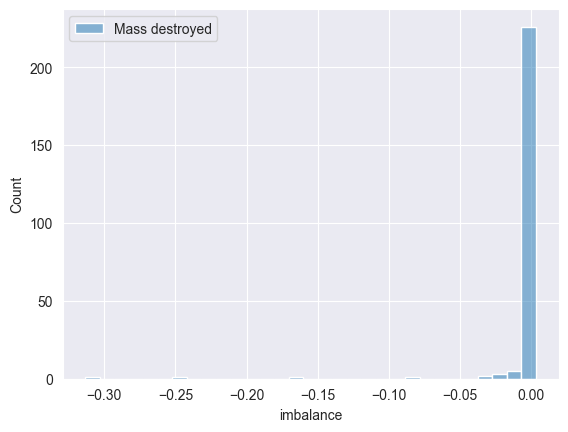

In [42]:
#correct very small negative delta values
print(delta.sum())
#histogram
sns.histplot(data=delta, color='yellow', bins='auto',log_scale=False)
plt.xlabel("imbalance")
plt.show()

In [44]:
#set all values in delta that are close to 0 (less than 1g) to 0
delta = delta.where(delta.abs() >= 1e-4, 0)
delta.fillna(0)
print(delta.sum())

Mass destroyed   -0.995176
dtype: float64


In [45]:
#physical supply matrix
V_mass = alpha * V
V_mass = V_mass.fillna(0)
V_mass.to_csv(f'V_mass.csv')

#physical use matrix
U_mass = U.mul(alpha_prime['Plastic intensity'], axis=0)
U_mass = U_mass.fillna(0)
U_mass.to_csv(f'U_mass.csv')

#physical import vector
v_imp_mass = v_imp.mul(alpha_prime['Plastic intensity'], axis=0)
v_imp_mass = v_imp_mass.fillna(0)
v_imp_mass.to_csv(f'v_imp_mass.csv')

#physical final demand matrix
Y_mass = Y.mul(alpha_prime['Plastic intensity'], axis=0)
Y_mass = Y_mass.fillna(0)
Y_mass.to_csv(f'Y_mass.csv')

#physical environmental extension
values = U_mass.T.stack()
F_mass = gamma.mul(values, axis=0)
assert set(gamma.index) <= set(values.index) #raises error if gamma indices don't match the U_mass tuples
F_mass = F_mass.fillna(0)
F_mass.to_csv(f'F_mass.csv')

#add U_pack_mass
U_pack_mass = U_pack.mul(alpha_prime['Plastic intensity'], axis=0)
U_pack_mass = U_pack_mass.fillna(0)
U_pack_mass.to_csv(f'U_pack_mass.csv')

F_mass

Waste  \
Industries                                         Products                                                    
Crop production (except cannabis, greenhouse, n... Canola (including rapeseed)                           0.0   
                                                   Oilseeds (except canola)                              0.0   
                                                   Wheat                                                 0.0   
                                                   Grains (except wheat)                                 0.0   
                                                   Fresh potatoes                                        0.0   
...                                                                                                      ...   
Other aboriginal government services               Defence services                                      0.0   
                                                   Other federal government services                     0.0   
                                                   Other provincial and territorial government ser...    0.0   
                                                   Other municipal government services                   0.0   
                                                   Other aboriginal government services                  0.0   

                                                                                                       Capital formation  \
Industries                                         Products                                                                
Crop production (except cannabis, greenhouse, n... Canola (including rapeseed)                                       0.0   
                                                   Oilseeds (except canola)                                          0.0   
                                                   Wheat                                                             0.0   
                                                   Grains (except wheat)                                             0.0   
                                                   Fresh potatoes                                                    0.0   
...                                                                                                                  ...   
Other aboriginal government services               Defence services                                                  0.0   
                                                   Other federal government services                                 0.0   
                                                   Other provincial and territorial government ser...                0.0   
                                                   Other municipal government services                               0.0   
                                                   Other aboriginal government services                              0.0   

                                                                                                       Environment  
Industries                                         Products                                                         
Crop production (except cannabis, greenhouse, n... Canola (including rapeseed)                                 0.0  
                                                   Oilseeds (except canola)                                    0.0  
                                                   Wheat                                                       0.0  
                                                   Grains (except wheat)                                       0.0  
                                                   Fresh potatoes                                              0.0  
...                                                                                                            ...  
Other aboriginal government services               Defence services                              

## Constructing the MFA

In [46]:
#processing of Y_mass into for the MFA meaningful flows
#create new Y_mass_mfa dataframe
col_list = ['Final consumption expenditure',
            'Private imports',
            'Private exports',
            'Gross fixed capital formation, Construction',
            'Gross fixed capital formation, Machinery and equipment',
            'Used cars and equipment and scrap',
            'Gross fixed capital formation, Intellectual property products',
            'Changes to inventories',
            'International exports'
            ]
Y_mass_MFA = pd.DataFrame(index=Y_mass.index,columns=col_list)

#Final consumption expenditure
cols = Y_mass.columns[np.r_[0:99,101:110]]
Y_mass_MFA.loc[:,'Final consumption expenditure'] = Y_mass.loc[:, cols].sum(axis=1)
Y_mass_MFA.loc[:,'Private imports'] = Y_mass.loc[:,'Expenditure by Canadians abroad']
Y_mass_MFA.loc[:,'Private exports'] = abs(Y_mass.loc[:,'Expenditure by non-residents in Canada'])

#Gross fixed capital formation, Construction
cols = Y_mass.columns[110:164] 
Y_mass_MFA.loc[:,'Gross fixed capital formation, Construction'] = Y_mass.loc[:, cols].sum(axis=1)

#Gross fixed capital formation, Machinery and equipment
cols = Y_mass.columns[np.r_[164:208,209,211:219]]
Y_mass_MFA.loc[:,'Gross fixed capital formation, Machinery and equipment'] = Y_mass.loc[:, cols].sum(axis=1)
cols = Y_mass.columns[np.r_[208,210,219]] 
Y_mass_MFA.loc[:,'Used cars and equipment and scrap'] = Y_mass.loc[:, cols].sum(axis=1) #if negative, this means it comes from the National stock of last year to the capital (let's say)!

#Gross fixed capital formation, Intellectual property products
cols = Y_mass.columns[220:273]
Y_mass_MFA.loc[:,'Gross fixed capital formation, Intellectual property products'] = Y_mass.loc[:, cols].sum(axis=1)

#Changes to inventories
cols = Y_mass.columns[np.r_[273,274]]
Y_mass_MFA.loc[:,'Changes to inventories'] = Y_mass.loc[:, cols].sum(axis=1) #if negative, this means it comes from the National stock of last year to the market!


#International exports
cols = Y_mass.columns[np.r_[275,276]]
Y_mass_MFA.loc[:,'International exports'] = Y_mass.loc[:, cols].sum(axis=1)

Y_mass_MFA

,Final consumption expenditure,Private imports,Private exports,"Gross fixed capital formation, Construction","Gross fixed capital formation, Machinery and equipment",Used cars and equipment and scrap,"Gross fixed capital formation, Intellectual property products",Changes to inventories,International exports
Products,,,,,,,,,
Canola (including rapeseed),0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
Oilseeds (except canola),0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
Wheat,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
Grains (except wheat),0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
Fresh potatoes,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
...,...,...,...,...,...,...,...,...,...
Defence services,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
Other federal government services,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
Other provincial and territorial government services,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


In [47]:
Y_mass_MFA.sum() #kg

Final consumption expenditure                                    1978937586.692915
Private imports                                                    56710337.718227
Private exports                                                    30030045.123558
Gross fixed capital formation, Construction                      1517651197.374733
Gross fixed capital formation, Machinery and equipment            828465041.453591
Used cars and equipment and scrap                                  -1608150.751279
Gross fixed capital formation, Intellectual property products     828465041.453591
Changes to inventories                                           -131944237.607064
International exports                                             7897454269.31254
dtype: object

### Setting up the first MFA dataframe (with markets and industries)

In [48]:
#this is the format of the MFA dataframe:
df_MFA = pd.DataFrame(columns=['Product','From','To','Quantity (kg)'])
rows_list = []

#the 'from' is defined by:
#v_imp_mass: imports
mask = v_imp_mass['International imports'] != 0
subset = v_imp_mass.loc[mask, 'International imports'].reset_index()
subset.columns = ['Product', 'Quantity (kg)']
new_rows = pd.DataFrame({
    'Product': subset['Product'],
    'From': 'International imports',
    'To': 'Market ' + subset['Product'],
    'Quantity (kg)': subset['Quantity (kg)']
})
#for each source dataframe:
rows_list.append(new_rows)

#V_mass: supply to market
stacked = V_mass.stack()
stacked = stacked[stacked != 0]
stacked = stacked.reset_index()
stacked.columns = ['Product', 'Industry', 'Quantity (kg)']
new_rows = pd.DataFrame({
    'Product': stacked['Product'],
    'From': stacked['Industry'],
    'To': 'Market ' + stacked['Product'],
    'Quantity (kg)': stacked['Quantity (kg)']
})
rows_list.append(new_rows)


#the 'to' is defined by:
#U_mass: use by industry
stacked = U_mass.stack()
stacked = stacked[stacked != 0]
stacked = stacked.reset_index()
stacked.columns = ['Product', 'Industry', 'Quantity (kg)']
new_rows = pd.DataFrame({
    'Product': stacked['Product'],
    'From': 'Market ' + stacked['Product'],
    'To': stacked['Industry'],
    'Quantity (kg)': stacked['Quantity (kg)']
})
rows_list.append(new_rows)



list_to = ['Final consumption expenditure',
            'Private exports',
            'Gross fixed capital formation, Construction',
            'Gross fixed capital formation, Machinery and equipment',
            'Gross fixed capital formation, Intellectual property products',
            'International exports'
           ]
Y_mass_to = Y_mass_MFA.loc[:, list_to] #intermediate dataframe
stacked = Y_mass_to.stack()
stacked = stacked[stacked != 0]
stacked = stacked.reset_index()
stacked.columns = ['Product', 'Industry', 'Quantity (kg)']
new_rows = pd.DataFrame({
    'Product': stacked['Product'],
    'From': 'Market ' + stacked['Product'],
    'To': stacked['Industry'],
    'Quantity (kg)': stacked['Quantity (kg)']
})
rows_list.append(new_rows)


#both 'from' and 'to' are defined by:
#beta: generation by a certain industry
stacked = beta[beta != 0]
stacked = stacked.reset_index()
stacked.columns = ['Industry', 'Quantity (kg)']
new_rows = pd.DataFrame({
    'Product': 'Plastic resins',
    'From': 'Sum of all domestic Plastic resin production',  
    'To': stacked['Industry'],
    'Quantity (kg)': stacked['Quantity (kg)']
})
rows_list.append(new_rows)

#delta: plastic destroyed
#for all the bigger imbalance flows
#instead of silently dropping negative values in delta, lets flip the direction of the flow:
stacked = delta[delta != 0]
stacked = stacked.reset_index()
stacked.columns = ['Industry', 'Quantity (kg)']
positive = stacked[stacked['Quantity (kg)'] > 0]
negative = stacked[stacked['Quantity (kg)'] < 0]
new_rows_pos = pd.DataFrame({
    'Product': 'Plastic resins',
    'From': positive['Industry'],
    'To': 'Destruction',
    'Quantity (kg)': positive['Quantity (kg)']
})
new_rows_neg = pd.DataFrame({
    'Product': 'Plastic resins',
    'From': 'Destruction',
    'To': negative['Industry'],
    'Quantity (kg)': negative['Quantity (kg)'].abs()
})
rows_list.append(new_rows_pos)
rows_list.append(new_rows_neg)

#F_mass: flow from an industry to the environmental extension
stacked = F_mass.stack()
stacked = stacked[stacked != 0]
stacked = stacked.reset_index()
stacked.columns = ['Industry', 'Product', 'f', 'Quantity (kg)']  # order = level0, level1, column, value

new_rows = pd.DataFrame({
    'Product': stacked['Product'],
    'From': stacked['Industry'],
    'To': stacked['f'],
    'Quantity (kg)': stacked['Quantity (kg)']
})
rows_list.append(new_rows)


#Y_mass_MFA
#list_from = ['Private imports',
#             'Used cars and equipment and scrap', #from National stock to Capital formation (Gross fixed capital formation, Machinery and equipment) since negative
#             'Changes to inventories' #from National stock to Market since negative]
Y_mass_priv = Y_mass_MFA.loc[:, 'Private imports'] #intermediate dataframe
stacked = Y_mass_priv[Y_mass_priv != 0]
stacked = stacked.reset_index()
stacked.columns = ['Product', 'Quantity (kg)']
new_rows = pd.DataFrame({
    'Product': stacked['Product'],
    'From': 'Private imports',
    'To': 'Final consumption expenditure',
    'Quantity (kg)': stacked['Quantity (kg)']
})
rows_list.append(new_rows)

Y_mass_car = Y_mass_MFA.loc[:, 'Used cars and equipment and scrap'] #intermediate dataframe
stacked = Y_mass_car[Y_mass_car != 0]
stacked = stacked.reset_index()
stacked.columns = ['Product', 'Quantity (kg)']
new_rows = pd.DataFrame({
    'Product': stacked['Product'],
    'From': 'National stock',
    'To': 'Gross fixed capital formation, Machinery and equipment',
    'Quantity (kg)': abs(stacked['Quantity (kg)'])
})
rows_list.append(new_rows)

Y_mass_changes = Y_mass_MFA.loc[:, 'Changes to inventories'] #intermediate dataframe
stacked = Y_mass_changes[Y_mass_car != 0]
stacked = stacked.reset_index()
stacked.columns = ['Product', 'Quantity (kg)']
new_rows = pd.DataFrame({
    'Product': stacked['Product'],
    'From': 'National stock',
    'To': 'Market ' + stacked['Product'],
    'Quantity (kg)': abs(stacked['Quantity (kg)'])
})
rows_list.append(new_rows)





#adding U_pack_mass
#use of packaging by industry defined in U_pack_mass, then sending packaging from this industry to waste
#U_pack_mass: use of packaging by industry
stacked = U_pack_mass.stack()
stacked = stacked[stacked != 0]
stacked = stacked.reset_index()
stacked.columns = ['Product', 'Industry', 'Quantity (kg)']
new_rows = pd.DataFrame({
    'Product': stacked['Product'],
    'From': 'Market ' + stacked['Product'],
    'To': stacked['Industry'],
    'Quantity (kg)': stacked['Quantity (kg)']
})
rows_list.append(new_rows)

#supply of these packaging products by industry to waste
stacked = U_pack_mass.stack()
stacked = stacked[stacked != 0]
stacked = stacked.reset_index()
stacked.columns = ['Product', 'Industry', 'Quantity (kg)']
new_rows = pd.DataFrame({
    'Product': stacked['Product'],
    'From': stacked['Industry'],
    'To': 'Waste',
    'Quantity (kg)': stacked['Quantity (kg)']
})
rows_list.append(new_rows)

df_MFA = pd.concat(rows_list, ignore_index=True)

#some last minute modifications
#df_MFA[df_MFA =='Changes to inventories'] = 'National stock'
df_MFA = df_MFA.dropna()
df_MFA.to_csv(f'df_MFA.csv')
df_MFA

,Product,From,To,Quantity (kg)
0,"Fibre, yarn and thread",International imports,"Market Fibre, yarn and thread",11580147.488093
1,Fabrics,International imports,Market Fabrics,127441841.632082
2,"Carpets, rugs and mats",International imports,"Market Carpets, rugs and mats",56926179.511356
3,Other textile furnishings,International imports,Market Other textile furnishings,35738100.123311
4,"Textile products, n.e.c.",International imports,"Market Textile products, n.e.c.",47084435.64197
...,...,...,...,...
24470,"Light gauge metal containers, crowns and closures","Arts, entertainment and recreation",Waste,1246.469509
24471,"Light gauge metal containers, crowns and closures",Defence services,Waste,296.38275
24472,"Light gauge metal containers, crowns and closures",Other federal government services (except defe...,Waste,2573.267053
24473,"Light gauge metal containers, crowns and closures",Other provincial and territorial government se...,Waste,2800.401497


In [49]:
#do we have any negative values left?
df_MFA['Quantity (kg)'].min()

2.8424244170918273e-06

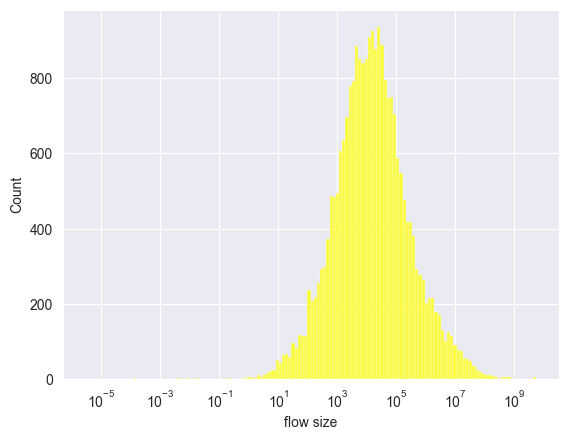

In [50]:
#histogram
sns.histplot(data=df_MFA['Quantity (kg)'], color='yellow', bins='auto',log_scale=True)
plt.xlabel("flow size")
plt.show()

Mass-balance check

In [51]:
#use current df_MFA
#check the balance of all nodes and total in and total out
#M_balance_total = pd.DataFrame(data=0,columns=['Node','In','Out','Difference'])

#get unique labels across From and To
unique_labels = pd.unique(df_MFA[['From', 'To']].values.ravel())

#sum of Quantity (kg) where label appears in From column
sum_From = df_MFA.groupby('From')['Quantity (kg)'].sum().rename('In')

#sum of Quantity (kg) where label appears in To column
sum_To = df_MFA.groupby('To')['Quantity (kg)'].sum().rename('Out')

#fill M_balance_total
M_balance_total = pd.DataFrame({'Node': unique_labels})
M_balance_total = M_balance_total.join(sum_From, on='Node').join(sum_To, on='Node').fillna(0)
M_balance_total['Difference'] = M_balance_total['In'] - M_balance_total['Out']
M_balance_total = M_balance_total.reset_index(drop=True)
M_balance_total.set_index('Node', inplace=True)
#M_balance_total.to_csv(f'260327_SUT-to-MFA_final demand disaggregation/df_MFA_v4.7_m-balance.csv')
#look at total in and out
print(M_balance_total['In'].sum())
print(M_balance_total['Out'].sum())

62304107815.72606
62304107815.72604


C:\Users\franz\AppData\Local\Temp\ipykernel_24716\1746729534.py:16: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  M_balance_total = M_balance_total.join(sum_From, on='Node').join(sum_To, on='Node').fillna(0)


### Market disaggregation

In [52]:
#Claude's cleaner version of the code
filtered = df_MFA[df_MFA['From'].str.contains('Market')]

results_markets = filtered[['Product', 'To', 'Quantity (kg)']].copy()

share_markets = filtered[['Product', 'To', 'Quantity (kg)']].copy()
share_markets['Quantity share'] = results_markets.groupby('Product')['Quantity (kg)'].transform(lambda x: x / x.sum())
share_markets = share_markets.drop(columns='Quantity (kg)')

df_MFA = df_MFA[~df_MFA['From'].str.contains('Market')]

market_to = df_MFA[df_MFA['To'].str.contains('Market')]

merged = market_to.merge(share_markets, on='Product')

merged['To'] = merged['To_y']
merged['Quantity (kg)'] = merged['Quantity (kg)'] * merged['Quantity share']

result = merged[['Product', 'From', 'To', 'Quantity (kg)']]

df_MFA = df_MFA[~df_MFA['To'].str.contains('Market')]
df_MFA_without_markets = pd.concat([df_MFA, result])
df_MFA_without_markets.to_csv(f'df_MFA_without_markets.csv', index=False)
df_MFA_without_markets

,Product,From,To,Quantity (kg)
11807,Plastic resins,Sum of all domestic Plastic resin production,Textile and textile product mills,1967812.232518
11808,Plastic resins,Sum of all domestic Plastic resin production,"Resin, synthetic rubber, and artificial and sy...",4849543868.751306
11809,Plastic resins,Sum of all domestic Plastic resin production,Pharmaceutical and medicine manufacturing,12285888.624257
11810,Plastic resins,Sum of all domestic Plastic resin production,"Paint, coating and adhesive manufacturing",461344.048098
11811,Plastic resins,Sum of all domestic Plastic resin production,Other chemical product manufacturing,448355730.027449
...,...,...,...,...
89118,Aircraft,National stock,Final consumption expenditure,19711.176676
89119,Aircraft,National stock,"Gross fixed capital formation, Construction",127589.869315
89120,Aircraft,National stock,"Gross fixed capital formation, Machinery and e...",127589.869315
89121,Aircraft,National stock,"Gross fixed capital formation, Intellectual pr...",127589.869315


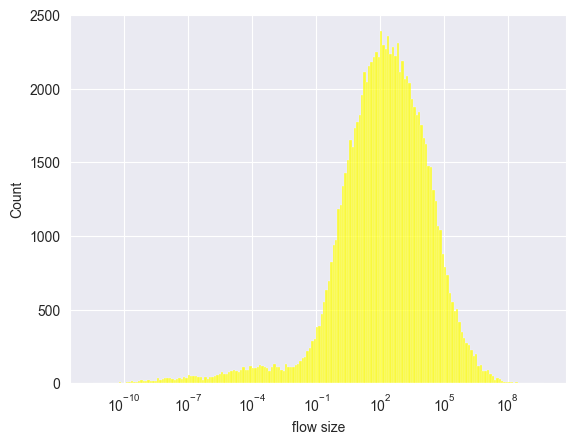

In [53]:
#histogram
sns.histplot(data=df_MFA_without_markets['Quantity (kg)'], color='yellow', bins='auto',log_scale=True)
plt.xlabel("flow size")
plt.show()

Mass-balance check

In [54]:
#use current df_MFA_without_markets

#check the balance of all nodes and total in and total out
#M_balance_total = pd.DataFrame(data=0,columns=['Node','In','Out','Difference'])

#get unique labels across From and To
unique_labels = pd.unique(df_MFA_without_markets[['From', 'To']].values.ravel())

#sum of Quantity (kg) where label appears in From column
sum_From = df_MFA_without_markets.groupby('From')['Quantity (kg)'].sum().rename('In')

#sum of Quantity (kg) where label appears in To column
sum_To = df_MFA_without_markets.groupby('To')['Quantity (kg)'].sum().rename('Out')

#fill M_balance_total
M_balance_total = pd.DataFrame({'Node': unique_labels})
M_balance_total = M_balance_total.join(sum_From, on='Node').join(sum_To, on='Node').fillna(0)
M_balance_total['Difference'] = M_balance_total['In'] - M_balance_total['Out']
M_balance_total = M_balance_total.reset_index(drop=True)
M_balance_total.set_index('Node', inplace=True)
#M_balance_total.to_csv(f'260327_SUT-to-MFA_final demand disaggregation/df_MFA_v4.7_m-balance.csv')
#look at total in and out
print(M_balance_total['In'].sum())
print(M_balance_total['Out'].sum())

35562083049.743286
35562083049.74322


C:\Users\franz\AppData\Local\Temp\ipykernel_24716\2275342400.py:17: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  M_balance_total = M_balance_total.join(sum_From, on='Node').join(sum_To, on='Node').fillna(0)


Group industries and products into archetypes

In [55]:
#import industry mapping table
Ind_archetypes = pd.read_excel('SI2_mapping_tables.xlsx', sheet_name='Industry-archetypes', index_col=0).fillna(0)

Ind_archetypes = Ind_archetypes.drop(columns=['Industry Code (NAICS)'], axis=0)
#create a big correspondence dataframe
df_correspondence = Ind_archetypes.copy(True)

#import Prod_Archetype (for colouring later)
Prod_archetypes = pd.read_excel('SI2_mapping_tables.xlsx', sheet_name='Product-archetypes', index_col=0).fillna(0)

df_correspondence.columns = df_correspondence.columns.astype(str)
df_correspondence_short = (
    df_correspondence.rename(columns={'(11) Agriculture, forestry, fishing and hunting': 'Agriculture',
                                      '(21) Mining, quarrying, and oil and gas extraction': 'Mining',
                                      '(22) Utilities, (23) Construction': 'Utilities & Construction',
                                      '(31-33) Manufacturing without (3252) and (3261)': 'Manufacturing',
                                      '(41) Wholesale, (44-45) retail trade, (48-49) transportation and warehousing ': 'Wholesale, Retail, Transport',
                                      '(51) Information and cultural activities, (52) Finance and insurance, (54) Professional, scientific and technical services, (55) Management of companies and enterprises, \n(56) Administrative and support, waste management and remediation services without (562)\n(61) Educational services, (62) Health care and social assistance, (71) Arts, entertainment and recreation (72) Accommodation and food services, (81) Other services, (91) Public administration, and other': 'Services',
                                      '(53) Real estate and rental and leasing': 'Real estate',
                                      '(562) Waste management and remediation services': 'Waste management services',
                                      '(3252) Resin, synthetic rubber, and artificial and synthetic fibres and filaments manufacturing':'Plastic resin manufacturing',
                                      '(3261) Plastic product manufacturing': 'Plastic product manufacturing',
                                      }))
df_correspondence_short

,Agriculture,Mining,Utilities & Construction,Plastic resin manufacturing,Plastic product manufacturing,Manufacturing,"Wholesale, Retail, Transport",Real estate,Waste management services,Services,...,Final consumption expenditure,Private imports,Private exports,Waste,Environment,International exports,Capital formation,National stock,Destruction,Sum of all domestic Plastic resin production
Industry,,,,,,,,,,,,,,,,,,,,,
"Crop production (except cannabis, greenhouse, nursery and floriculture production)",1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
"Greenhouse, nursery and floriculture production (except cannabis)",1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
Cannabis production (licensed),1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
Cannabis production (unlicensed),1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
Animal production (except aquaculture),1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
"Gross fixed capital formation, Intellectual property products",0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0
Capital formation,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0
National stock,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0


In [56]:
df_MFA_red = df_MFA_without_markets.copy()

#map nodes according to correspondence matrix
#reduce number of unique nodes in From and To of df_MFA_red with df_correspondence
mapping = df_correspondence_short.idxmax(axis=1)
df_MFA_red['From'] = df_MFA_red['From'].map(mapping).astype(str)
df_MFA_red['To'] = df_MFA_red['To'].map(mapping).astype(str)
df_MFA_red = df_MFA_red.groupby(['Product', 'From', 'To'], as_index=False)['Quantity (kg)'].sum()

#mapping products according to product archetypes
mapping = Prod_archetypes.idxmax(axis=1)
df_MFA_red['Product'] = df_MFA_red['Product'].map(mapping).astype(str)
df_MFA_red = df_MFA_red.groupby(['Product', 'From', 'To'], as_index=False)['Quantity (kg)'].sum()

df_MFA_red

,Product,From,To,Quantity (kg)
0,Buildings and infrastructure,Utilities & Construction,Capital formation,1003315082.943357
1,Buildings and infrastructure,Utilities & Construction,Final consumption expenditure,37303457.028959
2,Chemicals and synthetic products without Plast...,Agriculture,Capital formation,1361821.377187
3,Chemicals and synthetic products without Plast...,Agriculture,Environment,25855.347466
4,Chemicals and synthetic products without Plast...,International imports,Agriculture,605196.843455
...,...,...,...,...
854,Wood-related products,Services,Capital formation,51216.089687
855,Wood-related products,Utilities & Construction,Capital formation,6958755.448244
856,Wood-related products,Utilities & Construction,Environment,115420.674524
857,Wood-related products,Utilities & Construction,Waste,816933.263809


In [58]:
#colour and map products to archetypes
#add column for colour
df_MFA_coloured = pd.DataFrame(df_MFA_red, columns=['Product', 'From', 'To', 'Quantity (kg)', 'Colour_HEX'])

#get categorical colour map for 25 distinct colours
cmap1 = matplotlib.colormaps.get_cmap('tab20')
cmap2 = matplotlib.colormaps.get_cmap('tab20b')  #because we need more than 20 distinct colours...    
#use colour map related to product archetypes
color_map = {
    #Greens — chemicals, plastics
    'Plastic resins': mcolors.to_hex('lightgrey'),  #or 'grey'
    'Plastic bags': mcolors.to_hex(cmap2(4 / 19)),
    'Plastic films and non-rigid sheets': mcolors.to_hex(cmap2(5 / 19)),
    'Motor vehicle plastic parts': mcolors.to_hex(cmap2(3 / 19)),
    # Remaining plastic products — reuse greens
    'Plastic and foam building and construction materials': mcolors.to_hex(cmap2(8 / 19)),
    'Foam products (except for construction)':             mcolors.to_hex(cmap2(9 / 19)),
    'Plastic bottles':                                     mcolors.to_hex(cmap2(10 / 19)),
    'Plastic products, n.e.c.':                            mcolors.to_hex(cmap2(11 / 19)),
    'Rubber and plastic hoses and belts':                  mcolors.to_hex(cmap2(6 / 19)),
    'Plastic profile shapes':                              mcolors.to_hex(cmap2(7 / 19)),
    'Waste and scrap of plastic and rubber':               mcolors.to_hex(cmap2(12 / 19)),
    #Blues - wood, paper, natural materials
    'Wood-related products': mcolors.to_hex(cmap2(0 / 19)),
    'Paper-related products': mcolors.to_hex(cmap2(1 / 19)),
    #'Processed food products': mcolors.to_hex(cmap2(2 / 19)),
    #Other — environment, waste
    'Buildings and infrastructure': mcolors.to_hex(cmap2(13 / 19)),
    'Hardware, machinery, equipment, and vehicles': mcolors.to_hex(cmap2(14 / 19)),
    'Chemicals and synthetic products without Plastic resins': mcolors.to_hex(cmap2(15 / 19)),
    #Pinks/reds — consumer goods, clothes
    'Clothes and textiles': mcolors.to_hex(cmap2(16 / 19)),
    'Consumer goods': mcolors.to_hex(cmap2(17 / 19)),
    'Other supplies': mcolors.to_hex(cmap2(18 / 19)),
}

#add colour corresponding to product archetype
df_MFA_coloured['Colour_HEX'] = df_MFA_coloured['Product'].map(color_map)

df_MFA_coloured

,Product,From,To,Quantity (kg),Colour_HEX
0,Buildings and infrastructure,Utilities & Construction,Capital formation,1003315082.943357,#ad494a
1,Buildings and infrastructure,Utilities & Construction,Final consumption expenditure,37303457.028959,#ad494a
2,Chemicals and synthetic products without Plast...,Agriculture,Capital formation,1361821.377187,#e7969c
3,Chemicals and synthetic products without Plast...,Agriculture,Environment,25855.347466,#e7969c
4,Chemicals and synthetic products without Plast...,International imports,Agriculture,605196.843455,#e7969c
...,...,...,...,...,...
854,Wood-related products,Services,Capital formation,51216.089687,#393b79
855,Wood-related products,Utilities & Construction,Capital formation,6958755.448244,#393b79
856,Wood-related products,Utilities & Construction,Environment,115420.674524,#393b79
857,Wood-related products,Utilities & Construction,Waste,816933.263809,#393b79


In [59]:
#scale df to tonnes
df_MFA_scaled = df_MFA_coloured.copy(True)
#scale Quantity to tonnes
df_MFA_scaled['Quantity (kg)'] = df_MFA_scaled['Quantity (kg)'] / 1e3
#rename column
df_MFA_scaled = df_MFA_scaled.rename(columns={'Quantity (kg)':'Quantity (t)'})

df_MFA_scaled.to_csv(f'df_MFA_coloured&scaled.csv')
df_MFA_scaled

,Product,From,To,Quantity (t),Colour_HEX
0,Buildings and infrastructure,Utilities & Construction,Capital formation,1003315.082943,#ad494a
1,Buildings and infrastructure,Utilities & Construction,Final consumption expenditure,37303.457029,#ad494a
2,Chemicals and synthetic products without Plast...,Agriculture,Capital formation,1361.821377,#e7969c
3,Chemicals and synthetic products without Plast...,Agriculture,Environment,25.855347,#e7969c
4,Chemicals and synthetic products without Plast...,International imports,Agriculture,605.196843,#e7969c
...,...,...,...,...,...
854,Wood-related products,Services,Capital formation,51.21609,#393b79
855,Wood-related products,Utilities & Construction,Capital formation,6958.755448,#393b79
856,Wood-related products,Utilities & Construction,Environment,115.420675,#393b79
857,Wood-related products,Utilities & Construction,Waste,816.933264,#393b79


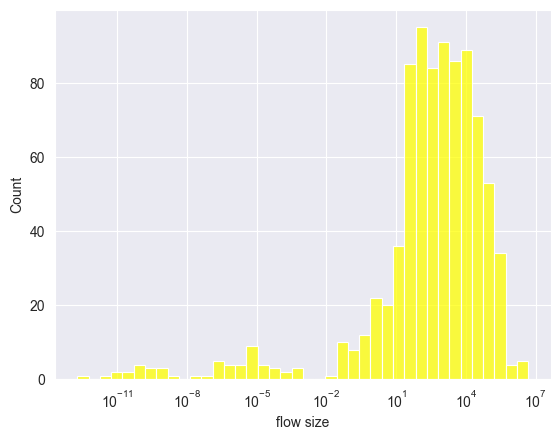

In [60]:
#histogram
sns.histplot(data=df_MFA_scaled['Quantity (t)'], color='yellow', bins='auto',log_scale=True)
plt.xlabel("flow size")
plt.show()

### Calculating some reference numbers

In [61]:
#mass of Plastic resins in International imports
mask = (df_MFA_scaled['From'] == 'International imports') & (df_MFA_scaled['Product'] == 'Plastic resins')
total = df_MFA_scaled.loc[mask, 'Quantity (t)'].sum()
total #in t

5476591.439902711

In [62]:
#mass of Plastic resins in International exports
mask = (df_MFA_scaled['To'] == 'International exports') & (df_MFA_scaled['Product'] == 'Plastic resins')
total = df_MFA_scaled.loc[mask, 'Quantity (t)'].sum()
total #in t

4824758.3787409235

In [63]:
#mass of total plastic in Final demand (Final consumption expenditure, Waste, Capital formation)
mask = (df_MFA_scaled['To'] == 'Final consumption expenditure')
total_fd = df_MFA_scaled.loc[mask, 'Quantity (t)'].sum()
mask = (df_MFA_scaled['To'] == 'Waste') #& (df_MFA_scaled['To'] == 'Capital formation')
total_w = df_MFA_scaled.loc[mask, 'Quantity (t)'].sum()
mask = (df_MFA_scaled['To'] == 'Capital formation')
total_cp = df_MFA_scaled.loc[mask, 'Quantity (t)'].sum()
total = total_fd + total_w + total_cp #in t
total  #in t

9071115.349059945

In [64]:
#mass of total plastic in Waste
total_w #in t

2723719.6876546037

In [65]:
#mass of total plastic in the Environment
mask = (df_MFA_scaled['To'] == 'Environment')
total_e = df_MFA_scaled.loc[mask, 'Quantity (t)'].sum()
total_e #in t

10411.486793993494